## Experiment 2: Interacting with Web APIs

**Aim:** To interact with a weather API to retrieve weather data for a specific location and perform data modeling and visualization to analyze weather patterns over time.

In [1]:
# A52 Dipanshu Ambilkar
import requests
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
url = "https://api.open-meteo.com/v1/forecast"
p = {"latitude": 18.52, "longitude": 73.85, "hourly": "temperature_2m,relative_humidity_2m,wind_speed_10m,precipitation", "forecast_days": 7}
r = requests.get(url, params=p, timeout=30).json()
print("API response keys:", list(r.keys()))

API response keys: ['latitude', 'longitude', 'generationtime_ms', 'utc_offset_seconds', 'timezone', 'timezone_abbreviation', 'elevation', 'hourly_units', 'hourly']


In [3]:
h = r["hourly"]
df = pd.DataFrame({
    "time": pd.to_datetime(h["time"]),
    "temp": h["temperature_2m"],
    "humidity": h["relative_humidity_2m"],
    "wind": h["wind_speed_10m"],
    "rain": h["precipitation"],
})
df.head()

,time,temp,humidity,wind,rain
0,2026-11-01 00:00:00,22.5,80,10.2,0.0
1,2026-11-01 01:00:00,22.1,83,7.1,0.0
2,2026-11-01 02:00:00,22.8,82,7.1,0.0
3,2026-11-01 03:00:00,24.3,76,8.3,0.0
4,2026-11-01 04:00:00,26.2,69,11.2,0.0


In [4]:
print("shape:", df.shape)
print("missing values:")
print(df.isnull().sum())

shape: (168, 5)
missing values:
time        0
temp        0
humidity    0
wind        0
rain        0
dtype: int64


In [5]:
df = df.dropna()
print("rows after dropna:", len(df))

rows after dropna: 168


In [6]:
print("Avg temp:", df["temp"].mean())

Avg temp: 24.383333333333333


In [7]:
print("Max temp:", df["temp"].max(), " Min temp:", df["temp"].min())

Max temp: 30.1  Min temp: 19.1


In [8]:
df["date"] = df["time"].dt.date
daily = df.groupby("date").agg({"temp": "mean", "humidity": "mean", "wind": "mean", "rain": "sum"})
print(daily)

                 temp   humidity      wind  rain
date                                            
2026-11-01  24.587500  78.041667  6.300000   7.4
2026-11-02  24.112500  84.000000  5.125000   3.1
2026-11-03  24.204167  80.750000  5.858333   0.9
2026-11-04  24.133333  80.833333  5.641667   1.0
2026-11-05  24.212500  78.916667  7.683333   0.3
2026-11-06  24.429167  77.916667  9.833333   1.2
2026-11-07  25.004167  66.583333  7.312500   0.0


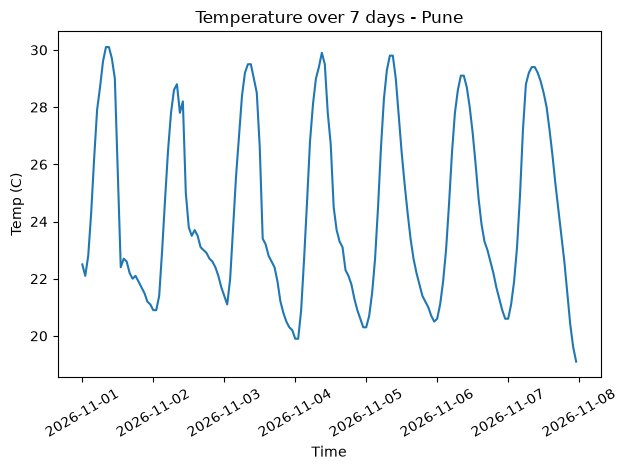

In [9]:
plt.plot(df["time"], df["temp"])
plt.title("Temperature over 7 days - Pune")
plt.xlabel("Time")
plt.ylabel("Temp (C)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

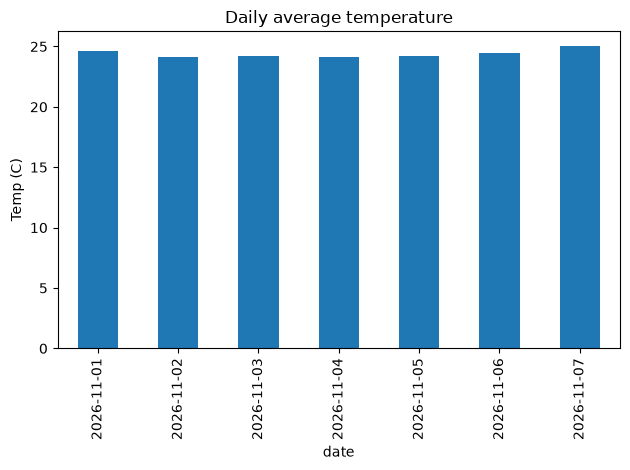

In [10]:
daily["temp"].plot(kind="bar")
plt.title("Daily average temperature")
plt.ylabel("Temp (C)")
plt.tight_layout()
plt.show()

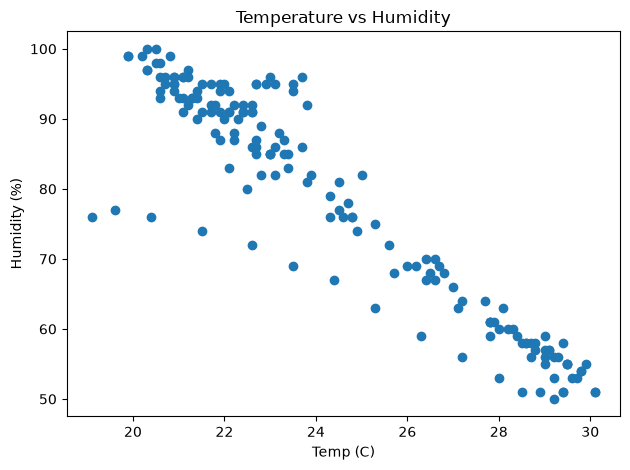

In [11]:
plt.scatter(df["temp"], df["humidity"])
plt.title("Temperature vs Humidity")
plt.xlabel("Temp (C)")
plt.ylabel("Humidity (%)")
plt.tight_layout()
plt.show()

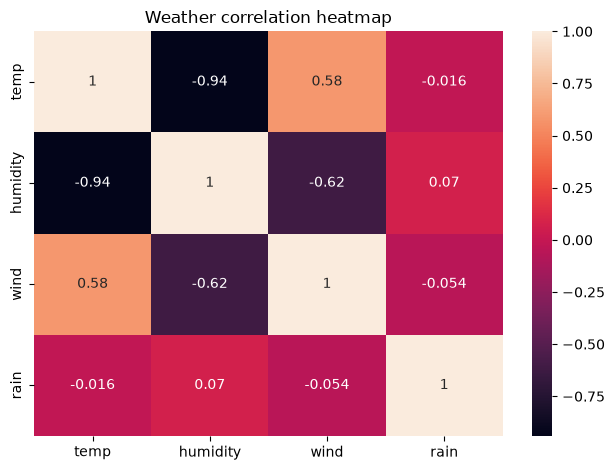

In [12]:
sns.heatmap(df[["temp", "humidity", "wind", "rain"]].corr(), annot=True)
plt.title("Weather correlation heatmap")
plt.tight_layout()
plt.show()

In [13]:
print("done")

done
